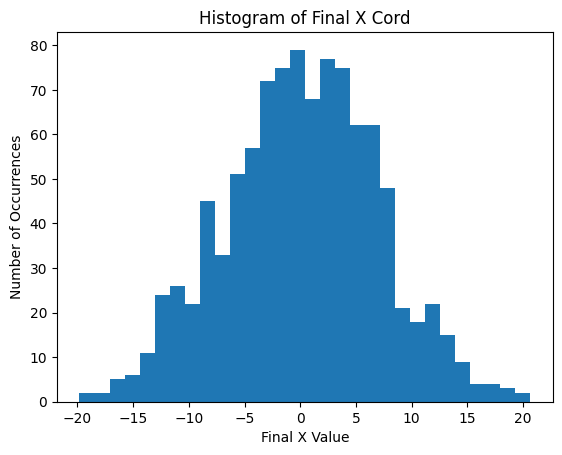

Mean of X = 0.15439394231512785
Mean of Y = 0.21376044760515242
Variance of X = 47.41406932143934


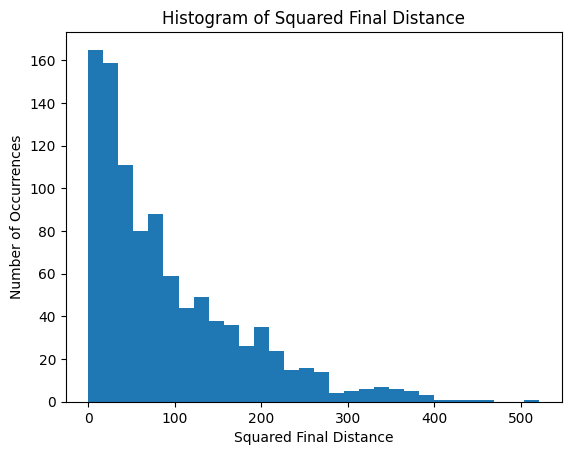

Mean squared distance = 93.01741510906518


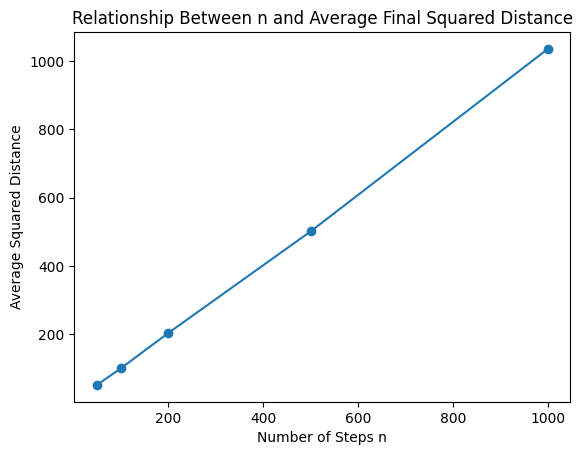

n values: [50, 100, 200, 500, 1000]
Average d2 values: [50.587, 98.855, 202.529, 500.709, 1036.208]
n values: [50, 100, 200, 500, 1000]
Mean biased X values: [28.803, 57.689, 115.431, 289.414, 577.859]
Mean biased Y values: [-0.056, 0.111, -0.359, -0.607, 0.823]
Mean biased squared distance values: [862.348, 3396.448, 13456.545, 84080.777, 334577.627]


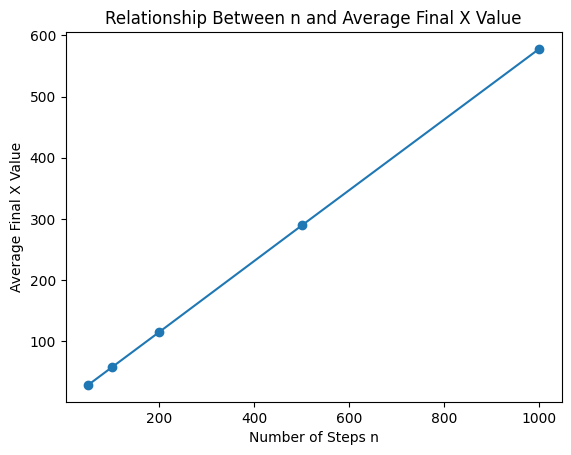

In [7]:
import math
import random
import matplotlib.pyplot as plt
import numpy as np

def random_walk(n):
    """simulates a random walk with n steps."""
    x, y = 0, 0

    for i in range(n):
        theta = random.uniform(0, 2 * math.pi)
        x += math.cos(theta)
        y += math.sin(theta)

    d2 = (x ** 2 + y ** 2)

    return x, y, d2

def biased_walk(n):
    """simulates a walk of n steps which is biased to travel eastwards."""
    x, y = 0, 0

    for i in range(n):
        theta = random.gauss(0, math.pi/3)
        x += math.cos(theta)
        y += math.sin(theta)

    d2 = (x ** 2 + y ** 2)

    return x, y, d2


M = 1000
final_x, final_y, final_d2 = [], [], []

for I in range(M):
    #simulates a random walk of step 100 a 1000 times.
    x, y, d2 = random_walk(100)
    final_x.append(x)
    final_y.append(y)
    final_d2.append(d2)

plt.hist(final_x, bins=30)
plt.xlabel("Final X Value")
plt.ylabel("Number of Occurrences")
plt.title("Histogram of Final X Cord")
plt.show()

#calcualtes average of x,y and variance of x.

x_mean = np.mean(final_x)
y_mean = np.mean(final_y)
x_var = np.var(final_x)
print("Mean of X =", x_mean)
print("Mean of Y =", y_mean)
print("Variance of X =", x_var)


plt.hist(final_d2, bins=30)
plt.xlabel("Squared Final Distance")
plt.ylabel("Number of Occurrences")
plt.title("Histogram of Squared Final Distance")
plt.show()

#claculates the mean squared distance.
d2_mean = np.mean(final_d2)
print("Mean squared distance =", d2_mean)

n_values = [50, 100, 200, 500, 1000]
#list of average squared distances.
d2_averages = []

for n in n_values:
    d2_values = []
    #simulates random walks for varying steps over a 1000 times and calculates the mean squared distance for that n number of steps.

    for i in range(M):
        x, y, d2 = random_walk(n)
        d2_values.append(d2)

    d2_averages.append(np.mean(d2_values))

plt.plot(n_values, d2_averages, marker='o')
plt.xlabel("Number of Steps n")
plt.ylabel("Average Squared Distance")
plt.title("Relationship Between n and Average Final Squared Distance")
plt.show()

print("n values:", n_values)
#makes the values of average squared distance a float and then rounds to 3 dp.
print("Average d2 values:", [round(float(x), 3) for x in d2_averages])


#lists of each variable mean on each run
biased_means_x, biased_means_y, biased_means_d2 = [], [], []

for n in n_values:
    biased_final_x, biased_final_y, biased_d2 = [], [], []
    #simulates random walks for varying steps over a 1000 times and calculates the mean squared distance for that n number of steps.

    for i in range(M):
        x, y, d2 = biased_walk(n)
        biased_final_x.append(x)
        biased_final_y.append(y)
        biased_d2.append(d2)

    biased_means_x.append(np.mean(biased_final_x))
    biased_means_y.append(np.mean(biased_final_y))
    biased_means_d2.append(np.mean(biased_d2))

print("n values:", n_values)

print("Mean biased X values:", [round(float(x), 3) for x in biased_means_x])
print("Mean biased Y values:", [round(float(x), 3) for x in biased_means_y])
print("Mean biased squared distance values:", [round(float(x), 3) for x in biased_means_d2])


plt.plot(n_values, biased_means_x, marker='o')
plt.xlabel("Number of Steps n")
plt.ylabel("Average Final X Value")
plt.title("Relationship Between n and Average Final X Value")
plt.show()
